<h1>Moteur de recherche d'images par le contenu — Approche classique : descripteurs locaux</h1>

Suite du premier projet (descripteurs globaux). Cette fois, chaque image est décrite par un ensemble de **descripteurs locaux** calculés autour de ses **points d'intérêt**. La similarité entre deux images est le **nombre de points mis en correspondance de façon réciproque**.

**Plan (travail demandé) :**
1. Détection des points d'intérêt : détecteur de **Harris** et détecteur **SIFT** (DoG).
2. Description de chaque point : **descripteur SIFT** (128 valeurs) et **invariants différentiels** (jet local).
3. Construction des matrices de similarité S (N×N, symétriques) et de leur version normalisée P (Pᵢᵢ = 1), enregistrées dans des fichiers.
4. Augmentation de la base par des transformations (rotation, translation, zoom, échelle, contraste, luminosité, bruit) et étude de la robustesse.
5. Comparaison avec l'approche globale de la première partie.

On utilise la même base d'images que dans la première partie (270 images COREL).

<h2>0. Configuration</h2>

In [2]:
import os, glob, re, random, time
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from scipy.ndimage import gaussian_filter
from skimage.feature import hog, local_binary_pattern

try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

BASE_DIR = os.environ.get('CBIR_DIR', '/content/drive/MyDrive/CBIR_DataSet')
if not os.path.isdir(os.path.join(BASE_DIR, 'obj_decoys')):
    candidats = []
    for motif in ['/content/drive/MyDrive/obj_decoys', '/content/drive/MyDrive/*/obj_decoys',
                  '/content/drive/MyDrive/*/*/obj_decoys', '/content/*/obj_decoys']:
        candidats += glob.glob(motif)
    if not candidats:
        raise FileNotFoundError("Dossier 'obj_decoys' introuvable : vérifie que CBIR_DataSet est bien dans ton Drive.")
    BASE_DIR = os.path.dirname(candidats[0])

DB_DIR  = os.path.join(BASE_DIR, 'obj_decoys')
REQ_DIR = os.path.join(BASE_DIR, 'img_requetes')
# Matrices S et P enregistrées dans ton propre Drive (le dossier partagé CBIR_DataSet est en lecture seule)
OUT_DIR = '/content/drive/MyDrive/resultats_descripteurs_locaux' if IN_COLAB else os.path.join(BASE_DIR, 'resultats_descripteurs_locaux')
try:
    os.makedirs(OUT_DIR, exist_ok=True)
except OSError:
    OUT_DIR = '/content/resultats_descripteurs_locaux'; os.makedirs(OUT_DIR, exist_ok=True)
print('Base     :', DB_DIR)
print('Requêtes :', REQ_DIR)
print('Sorties  :', OUT_DIR)
random.seed(0); np.random.seed(0)

Mounted at /content/drive
Base     : /content/drive/MyDrive/CBIR_DataSet/CBIR_DataSet/obj_decoys
Requêtes : /content/drive/MyDrive/CBIR_DataSet/CBIR_DataSet/img_requetes
Sorties  : /content/drive/MyDrive/resultats_descripteurs_locaux


<h2>1. Lecture de la base</h2>

In [3]:
EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def lire_image(chemin):
    img = cv2.imread(chemin)
    if img is None: raise ValueError(f'Image illisible : {chemin}')
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def lister_images(dossier):
    return sorted(p for p in glob.glob(os.path.join(dossier, '**', '*'), recursive=True) if p.lower().endswith(EXT))

IMAGES = {os.path.basename(p): lire_image(p) for p in lister_images(DB_DIR)}
NOMS_ORIG = list(IMAGES)
REQUETES = {os.path.basename(p): lire_image(p) for p in lister_images(REQ_DIR)}

# Catégorie COREL = chiffres avant les 3 derniers (ex. 382017.jpg -> 382)
def categorie(nom):
    stem = os.path.splitext(nom.split('__')[0])[0]
    return stem[:-3] if stem.isdigit() and len(stem) > 3 else stem

# Les deux « groupes » de l'énoncé, observés dans la première partie : 655 = leurres, les autres = châteaux
THEMES = {'655': 'leurres', '382': 'châteaux', '612': 'châteaux', '856': 'châteaux'}
def theme(nom): return THEMES.get(categorie(nom), categorie(nom))

# Retrouver dans la base les images identiques aux images requête
def retrouver_dans_base(img):
    for n, im in IMAGES.items():
        if im.shape == img.shape and np.abs(im.astype(int) - img.astype(int)).mean() < 2: return n
    return None
REQ_BASE = {r: retrouver_dans_base(im) for r, im in REQUETES.items()}

print(f'{len(IMAGES)} images, {len(REQUETES)} requêtes ; requêtes présentes dans la base : {REQ_BASE}')
print('Catégories :', pd.Series([categorie(n) for n in NOMS_ORIG]).value_counts().to_dict())
print('Tailles    :', pd.Series([f'{im.shape[1]}x{im.shape[0]}' for im in IMAGES.values()]).value_counts().to_dict())

270 images, 2 requêtes ; requêtes présentes dans la base : {'ImageRequete.jpg': '382017.jpg', 'ImageRequete2.jpg': '655083.jpg'}
Catégories : {'655': 83, '612': 76, '382': 60, '856': 51}
Tailles    : {'120x80': 270}


<h2>I. Construction d'un vecteur caractéristique par image</h2>
<h3>I.1 Détection des points d'intérêt : Harris et SIFT</h3>

- **Harris** détecte les **coins** (forte variation d'intensité dans deux directions). C'est un détecteur à une seule échelle : on fixe une taille de voisinage, et on calcule une **orientation dominante** (histogramme des gradients) pour que le descripteur SIFT soit invariant à la rotation.
- **SIFT** (différence de gaussiennes, DoG) détecte des **blobs** à plusieurs échelles. Chaque point a sa propre échelle et sa propre orientation : invariance à l'échelle et à la rotation.

Les images de la base sont très petites (120×80). Elles sont agrandies ×2 avant la détection pour obtenir assez de points. Le nombre de points est plafonné à `NB_MAX` par image pour que les deux détecteurs soient comparables.

In [4]:
AGRANDISSEMENT = 2      # images 120x80 -> 240x160 avant détection
NB_MAX = 120            # nombre maximum de points d'intérêt par image
TAILLE_HARRIS = 16      # taille (diamètre, en pixels) du voisinage décrit autour d'un coin de Harris

def preparer(img):
    g = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    return cv2.resize(g, None, fx=AGRANDISSEMENT, fy=AGRANDISSEMENT, interpolation=cv2.INTER_CUBIC)

def orientation_dominante(gris, x, y, rayon=8):
    """Orientation dominante (degrés) : pic de l'histogramme des orientations des gradients, pondéré par le module."""
    h, w = gris.shape
    x0, x1, y0, y1 = max(0, x - rayon), min(w, x + rayon + 1), max(0, y - rayon), min(h, y + rayon + 1)
    p = gris[y0:y1, x0:x1].astype(np.float32)
    if p.shape[0] < 3 or p.shape[1] < 3: return 0.0
    gy, gx = np.gradient(p)
    mag, ang = np.hypot(gx, gy), np.degrees(np.arctan2(gy, gx)) % 360
    yy, xx = np.mgrid[y0:y1, x0:x1]
    poids = mag * np.exp(-((xx - x) ** 2 + (yy - y) ** 2) / (2 * (rayon / 2) ** 2))
    hist, bords = np.histogram(ang, bins=36, range=(0, 360), weights=poids)
    return float(bords[np.argmax(hist)] + 5)

def points_harris(gris):
    coins = cv2.goodFeaturesToTrack(gris, maxCorners=NB_MAX, qualityLevel=0.01, minDistance=4,
                                    blockSize=3, useHarrisDetector=True, k=0.04)
    if coins is None: return []
    return [cv2.KeyPoint(float(x), float(y), TAILLE_HARRIS, orientation_dominante(gris, int(x), int(y)))
            for x, y in coins.reshape(-1, 2)]

SIFT = cv2.SIFT_create(nfeatures=NB_MAX, contrastThreshold=0.03)
def points_sift(gris):
    kps = SIFT.detect(gris, None)
    kps = sorted(kps, key=lambda k: -k.response)[:NB_MAX]
    return list(kps)

DETECTEURS = {'Harris': points_harris, 'SIFT': points_sift}

def detecter(img, detecteur):
    gris = preparer(img)
    kps = DETECTEURS[detecteur](gris)
    if not kps:   # image sans point détecté : un point au centre pour garder une description
        kps = [cv2.KeyPoint(gris.shape[1] / 2, gris.shape[0] / 2, TAILLE_HARRIS, 0)]
    return gris, kps

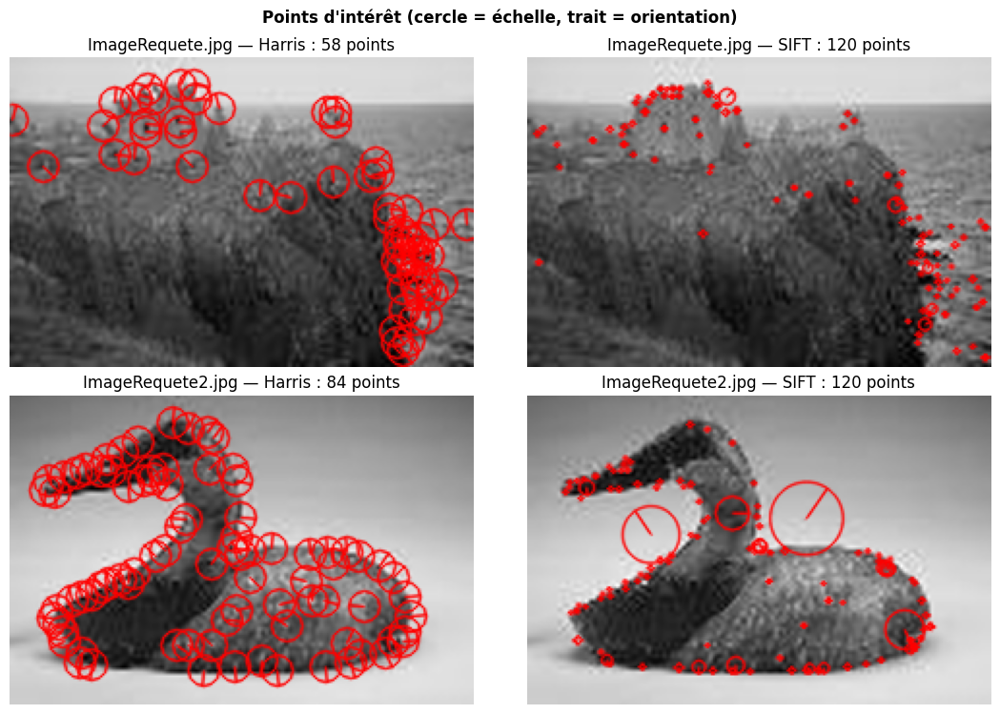

In [5]:
# Visualisation des points détectés sur les images requête
fig, axes = plt.subplots(len(REQUETES), 2, figsize=(11, 3.8 * len(REQUETES)), squeeze=False)
for i, (nom, img) in enumerate(REQUETES.items()):
    for j, det in enumerate(DETECTEURS):
        gris, kps = detecter(img, det)
        vis = cv2.drawKeypoints(cv2.cvtColor(gris, cv2.COLOR_GRAY2RGB), kps, None, color=(255, 0, 0),
                                flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
        axes[i, j].imshow(vis); axes[i, j].set_title(f'{nom} — {det} : {len(kps)} points'); axes[i, j].axis('off')
plt.suptitle('Points d\'intérêt (cercle = échelle, trait = orientation)', fontweight='bold'); plt.tight_layout(); plt.show()

<h3>I.2 Descripteurs locaux : SIFT et invariants différentiels</h3>

- **SIFT** : autour de chaque point, une grille 4×4 de cellules, chacune décrite par un histogramme de 8 orientations de gradient, soit **128 valeurs**. Le descripteur est normalisé (norme L2 = 1), comme demandé dans l'énoncé.
- **Invariants différentiels** (jet local, Koenderink, Schmid & Mohr) : on calcule les dérivées gaussiennes de l'image jusqu'à l'ordre 2 au point, puis des combinaisons **invariantes par rotation** :
  - $L$ (intensité lissée)
  - $L_x^2 + L_y^2$ (module du gradient au carré)
  - $L_{xx}L_x^2 + 2L_{xy}L_xL_y + L_{yy}L_y^2$ (dérivée seconde dans la direction du gradient)
  - $L_{xx} + L_{yy}$ (laplacien)
  - $L_{xx}^2 + 2L_{xy}^2 + L_{yy}^2$ (« énergie » de la courbure)

  Ces 5 invariants sont calculés à 3 échelles (σ = 1,5 ; 3 ; 6), avec des dérivées normalisées en échelle, soit **15 valeurs** par point. Chaque dimension est ensuite centrée-réduite sur toute la base, pour que les invariants aient le même poids dans la distance L2.

Le **vecteur caractéristique** d'une image est la concaténation des descripteurs de ses points : 128 × (nombre de points) pour SIFT. On le stocke sous forme de matrice (nombre de points × 128).

In [6]:
SIGMAS = (1.5, 3.0, 6.0)

def descripteurs_sift(gris, kps):
    kps, d = SIFT.compute(gris, kps)
    d = d.astype(np.float32)
    d /= np.linalg.norm(d, axis=1, keepdims=True) + 1e-12      # SIFT normalisés (norme L2 = 1)
    return kps, d

def invariants_differentiels(gris, kps):
    I = gris.astype(np.float32) / 255.0
    xs = np.clip(np.round([k.pt[0] for k in kps]).astype(int), 0, I.shape[1] - 1)
    ys = np.clip(np.round([k.pt[1] for k in kps]).astype(int), 0, I.shape[0] - 1)
    feats = []
    for s in SIGMAS:
        D = lambda oy, ox: gaussian_filter(I, s, order=(oy, ox))[ys, xs] * s ** (oy + ox)   # dérivée normalisée
        L, Lx, Ly, Lxx, Lxy, Lyy = D(0, 0), D(0, 1), D(1, 0), D(0, 2), D(1, 1), D(2, 0)
        feats += [L, Lx**2 + Ly**2, Lxx*Lx**2 + 2*Lxy*Lx*Ly + Lyy*Ly**2, Lxx + Lyy, Lxx**2 + 2*Lxy**2 + Lyy**2]
    return kps, np.stack(feats, axis=1).astype(np.float32)

DESCRIPTEURS = {'SIFT': descripteurs_sift, 'Invariants': invariants_differentiels}
# 4 combinaisons détecteur / descripteur
METHODES = [(det, desc) for det in DETECTEURS for desc in DESCRIPTEURS]
NOM_M = lambda m: f'{m[0]} + {m[1]}'

def decrire(img, methode):
    det, desc = methode
    gris, kps = detecter(img, det)
    kps, d = DESCRIPTEURS[desc](gris, kps)
    return np.unique(d, axis=0)   # supprime les descripteurs identiques (points détectés au même endroit avec 2 orientations)

def decrire_base(images):
    """{méthode: liste de matrices (nb_points x dim)} pour un dictionnaire d'images."""
    return {m: [decrire(im, m) for im in images.values()] for m in METHODES}

t0 = time.time()
DESC = decrire_base(IMAGES)
print(f'Description des {len(IMAGES)} images ({len(METHODES)} méthodes) en {time.time()-t0:.0f}s')

# Normalisation des invariants : centrage-réduction avec les statistiques de la base d'origine
STATS_INV = {}
for m in METHODES:
    if m[1] == 'Invariants':
        tout = np.vstack(DESC[m]); STATS_INV[m] = (tout.mean(0), tout.std(0) + 1e-8)
        DESC[m] = [(d - STATS_INV[m][0]) / STATS_INV[m][1] for d in DESC[m]]

stats = pd.DataFrame({NOM_M(m): {'dimension': DESC[m][0].shape[1],
                                 'points / image (moyenne)': np.mean([len(d) for d in DESC[m]]),
                                 'min': min(len(d) for d in DESC[m]), 'max': max(len(d) for d in DESC[m]),
                                 'taille moyenne du vecteur': np.mean([d.size for d in DESC[m]])}
                      for m in METHODES}).T
display(stats.round(1))
n0 = NOMS_ORIG[0]
print(f'Exemple : {n0} décrite par SIFT (détecteur SIFT) -> matrice {DESC[("SIFT", "SIFT")][0].shape}, '
      f'soit un vecteur de {DESC[("SIFT", "SIFT")][0].size} valeurs (128 x nombre de points)')

Description des 270 images (4 méthodes) en 57s


,dimension,points / image (moyenne),min,max,taille moyenne du vecteur
Harris + SIFT,128.0,110.4,31.0,120.0,14136.4
Harris + Invariants,15.0,110.4,31.0,120.0,1656.6
SIFT + SIFT,128.0,120.0,120.0,120.0,15360.0
SIFT + Invariants,15.0,96.2,72.0,113.0,1442.6


Exemple : 382001.jpg décrite par SIFT (détecteur SIFT) -> matrice (120, 128), soit un vecteur de 15360 valeurs (128 x nombre de points)


<h2>II. Création de la matrice de similarité</h2>

Pour deux images A (nₐ descripteurs) et B (n_b descripteurs) :
1. on calcule la matrice nₐ × n_b des distances L2 entre descripteurs ;
2. pour chaque descripteur de A, on repère son plus proche voisin dans B (A → B), et inversement (B → A) ;
3. on ne garde que les **couples réciproques** (Aᵢ → Bⱼ et Bⱼ → Aᵢ). Leur nombre est la similarité S(A, B).

S est symétrique par construction. Sᵢᵢ est le nombre de points de l'image i (chaque point est son propre plus proche voisin). La version normalisée est $P_{ij} = S_{ij} / \min(S_{ii}, S_{jj})$, avec Pᵢᵢ = 1.

In [7]:
def similarite(dA, dB):
    """Nombre de couples réciproques entre deux ensembles de descripteurs (implémentation directe de l'énoncé)."""
    D = np.sqrt(np.maximum((dA**2).sum(1)[:, None] + (dB**2).sum(1)[None, :] - 2 * dA @ dB.T, 0))  # (a) distances L2
    a_vers_b = D.argmin(axis=1)                                                                    # (a) Ai -> Bj
    b_vers_a = D.argmin(axis=0)                                                                    # (b) Bj -> Ai
    return int(sum(b_vers_a[j] == i for i, j in enumerate(a_vers_b)))                              # (c) couples réciproques

def matrice_S(lignes, colonnes):
    """S[i, j] = similarite(lignes[i], colonnes[j]). Version vectorisée : chaque image des lignes est
    comparée en une fois à tous les descripteurs des colonnes (même résultat que similarite, beaucoup plus rapide)."""
    tailles = np.array([len(d) for d in colonnes]); debuts = np.r_[0, np.cumsum(tailles)[:-1]]
    tout = np.vstack(colonnes).astype(np.float64); n2 = (tout ** 2).sum(1)
    seg = np.repeat(np.arange(len(colonnes)), tailles); T = len(tout)
    S = np.zeros((len(lignes), len(colonnes)), dtype=np.int32)
    for i, dA in enumerate(lignes):
        dA = dA.astype(np.float64)
        D = (dA ** 2).sum(1)[:, None] + n2[None, :] - 2 * dA @ tout.T        # distances² Ai - Bj (même ordre que L2)
        min_seg = np.minimum.reduceat(D, debuts, axis=1)
        idx = np.where(D == min_seg[:, seg], np.arange(T)[None, :], T)
        ab = np.minimum.reduceat(idx, debuts, axis=1)    # (a) indice du plus proche voisin de chaque Ai dans chaque image B
        ba = D.argmin(axis=0)                            # (b) plus proche voisin de chaque Bj dans A
        S[i] = (ba[ab] == np.arange(len(dA))[:, None]).sum(0)   # (c) couples réciproques
    return S

def symetriser(S):
    """Les deux sens de calcul (A contre B, B contre A) peuvent différer d'une unité à cause des égalités de
    distances et des arrondis : on garde le triangle supérieur et on le recopie, pour une matrice exactement symétrique."""
    return np.triu(S) + np.triu(S, 1).T

def normaliser(S):
    d = np.diag(S).astype(float)
    return S / np.minimum.outer(d, d)

# Vérification : la version vectorisée donne bien le même résultat que l'implémentation directe
m = ('SIFT', 'SIFT'); a, b = DESC[m][0], DESC[m][1]
verif = [(similarite(DESC[m][i], DESC[m][j]), matrice_S([DESC[m][i]], [DESC[m][j]])[0, 0]) for i, j in [(0, 1), (5, 200), (100, 150)]]
print('Vérification (implémentation directe, version vectorisée) :', verif)

Vérification (implémentation directe, version vectorisée) : [(36, np.int32(36)), (39, np.int32(39)), (42, np.int32(42))]


In [8]:
S, P = {}, {}
for m in METHODES:
    t0 = time.time()
    S[m] = symetriser(matrice_S(DESC[m], DESC[m]))
    P[m] = normaliser(S[m])
    print(f'{NOM_M(m):22s} : S {S[m].shape}, symétrique = {np.array_equal(S[m], S[m].T)}, '
          f'diag(P) = 1 : {np.allclose(np.diag(P[m]), 1)} ({time.time()-t0:.0f}s)')
    # 3. écriture des matrices dans des fichiers
    tag = NOM_M(m).replace(' + ', '_')
    pd.DataFrame(S[m], index=NOMS_ORIG, columns=NOMS_ORIG).to_csv(os.path.join(OUT_DIR, f'S_{tag}.csv'))
    pd.DataFrame(P[m], index=NOMS_ORIG, columns=NOMS_ORIG).round(4).to_csv(os.path.join(OUT_DIR, f'P_{tag}.csv'))
print('Matrices enregistrées dans', OUT_DIR, ':', sorted(os.listdir(OUT_DIR)))

Harris + SIFT          : S (270, 270), symétrique = True, diag(P) = 1 : True (33s)
Harris + Invariants    : S (270, 270), symétrique = True, diag(P) = 1 : True (26s)
SIFT + SIFT            : S (270, 270), symétrique = True, diag(P) = 1 : True (36s)
SIFT + Invariants      : S (270, 270), symétrique = True, diag(P) = 1 : True (21s)
Matrices enregistrées dans /content/drive/MyDrive/resultats_descripteurs_locaux : ['P_Harris_Invariants.csv', 'P_Harris_SIFT.csv', 'P_SIFT_Invariants.csv', 'P_SIFT_SIFT.csv', 'P_augmentee_Harris_Invariants.csv', 'P_augmentee_Harris_SIFT.csv', 'P_augmentee_SIFT_Invariants.csv', 'P_augmentee_SIFT_SIFT.csv', 'S_Harris_Invariants.csv', 'S_Harris_SIFT.csv', 'S_SIFT_Invariants.csv', 'S_SIFT_SIFT.csv', 'S_augmentee_Harris_Invariants.csv', 'S_augmentee_Harris_SIFT.csv', 'S_augmentee_SIFT_Invariants.csv', 'S_augmentee_SIFT_SIFT.csv']


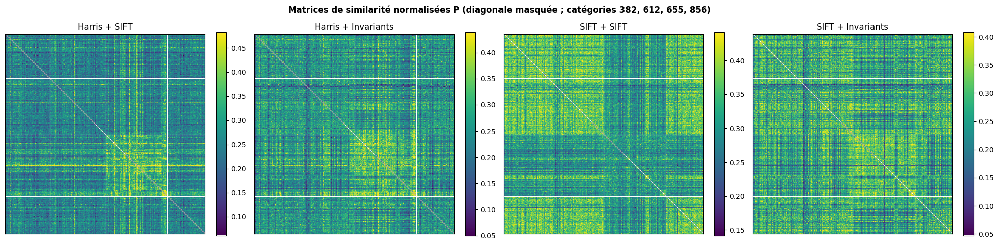

In [9]:
# Visualisation des matrices P (images triées par catégorie) : une bonne méthode donne des blocs clairs sur la diagonale
ordre = np.argsort([categorie(n) for n in NOMS_ORIG], kind='stable')
cats = [categorie(NOMS_ORIG[i]) for i in ordre]
limites = [k for k in range(1, len(cats)) if cats[k] != cats[k - 1]]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, m in zip(axes, METHODES):
    M = P[m][np.ix_(ordre, ordre)].copy(); np.fill_diagonal(M, np.nan)
    im = ax.imshow(M, cmap='viridis', vmax=np.nanpercentile(M, 99))
    for l in limites: ax.axhline(l - .5, color='w', lw=.8); ax.axvline(l - .5, color='w', lw=.8)
    ax.set_title(NOM_M(m)); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=.046)
plt.suptitle('Matrices de similarité normalisées P (diagonale masquée ; catégories ' + ', '.join(dict.fromkeys(cats)) + ')',
             fontweight='bold'); plt.tight_layout(); plt.show()

<h3>II.5 Images les plus similaires d'une image donnée</h3>

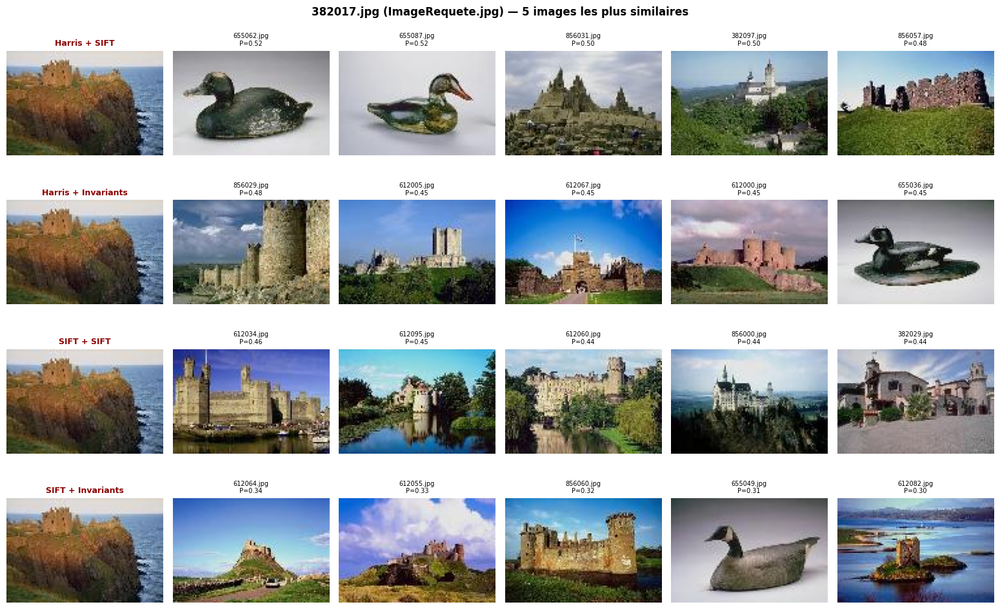

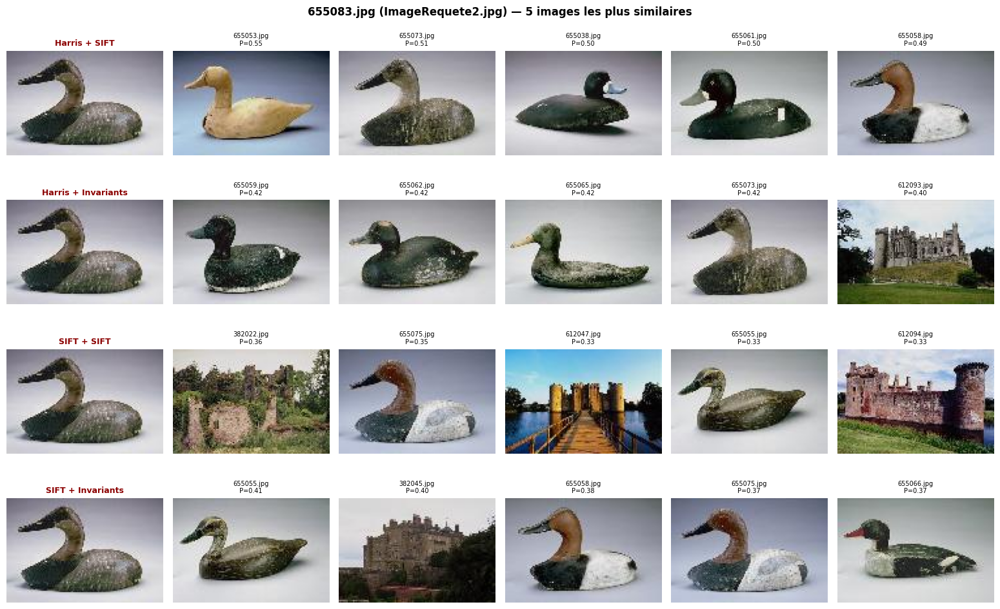

In [10]:
def plus_similaires(Pm, i, k=5, noms=None):
    noms = noms or NOMS_ORIG
    s = Pm[i].astype(float).copy(); s[i] = -np.inf
    o = np.argsort(-s)[:k]
    return [(noms[j], s[j]) for j in o]

def afficher_lignes(img_req, lignes, titre, images=None, k=5):
    images = images or IMAGES
    fig, axes = plt.subplots(len(lignes), k + 1, figsize=(2.6 * (k + 1), 2.5 * len(lignes)), squeeze=False)
    for r, (nom_ligne, res) in enumerate(lignes.items()):
        axes[r, 0].imshow(img_req); axes[r, 0].set_title(nom_ligne, fontsize=9, fontweight='bold', color='darkred')
        for c, (n, s) in enumerate(res[:k]):
            axes[r, c + 1].imshow(images[n]); axes[r, c + 1].set_title(f'{n}\nP={s:.2f}', fontsize=7)
    for ax in axes.ravel(): ax.axis('off')
    plt.suptitle(titre, fontweight='bold'); plt.tight_layout(); plt.show()

for req, nom_base in REQ_BASE.items():
    i = NOMS_ORIG.index(nom_base)
    afficher_lignes(IMAGES[nom_base], {NOM_M(m): plus_similaires(P[m], i) for m in METHODES},
                    f'{nom_base} ({req}) — 5 images les plus similaires')

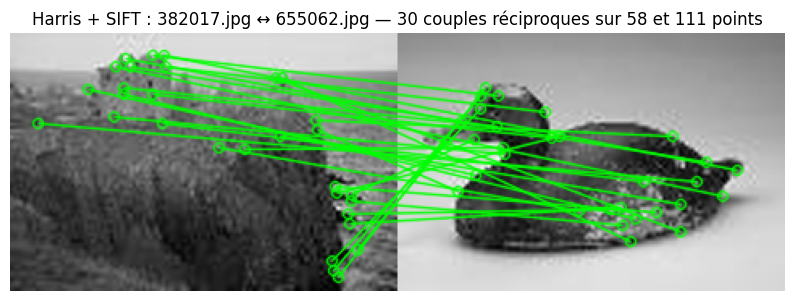

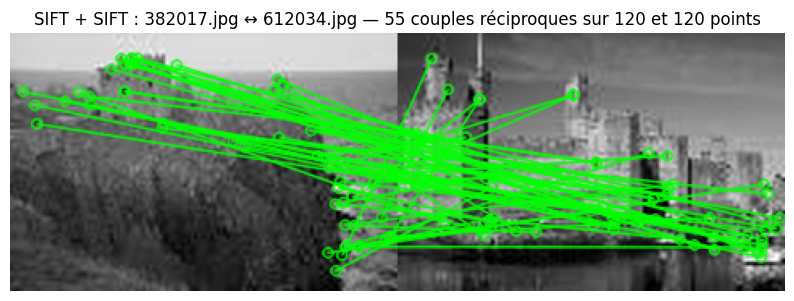

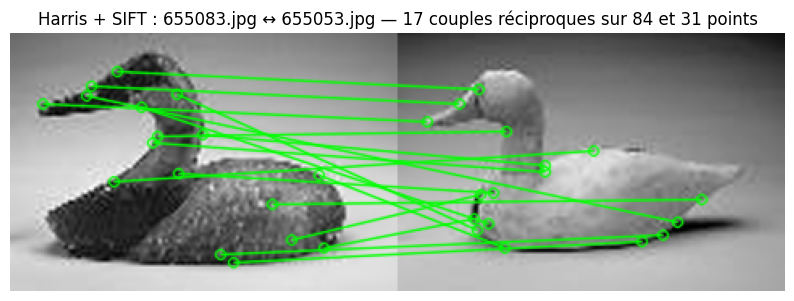

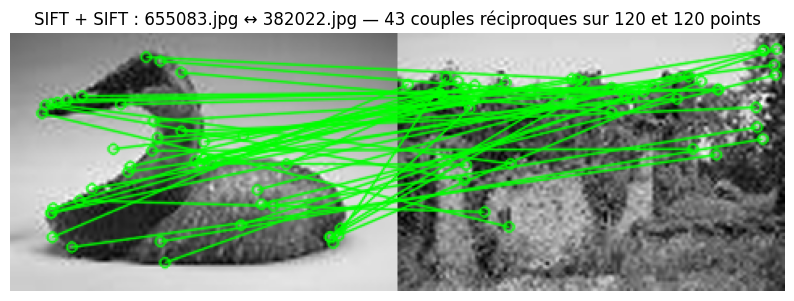

In [11]:
# Visualisation des couples réciproques entre chaque requête et son résultat le plus similaire (Harris + SIFT et SIFT + SIFT)
def couples_reciproques(dA, dB):
    D = ((dA[:, None, :] - dB[None, :, :]) ** 2).sum(-1)
    ab, ba = D.argmin(1), D.argmin(0)
    return [cv2.DMatch(i, int(j), float(D[i, j])) for i, j in enumerate(ab) if ba[j] == i]

for req, nom_base in REQ_BASE.items():
    i = NOMS_ORIG.index(nom_base)
    for m in [('Harris', 'SIFT'), ('SIFT', 'SIFT')]:
        meilleur = plus_similaires(P[m], i, 1)[0][0]
        gA, kA = detecter(IMAGES[nom_base], m[0]); kA, dA = descripteurs_sift(gA, kA)
        gB, kB = detecter(IMAGES[meilleur], m[0]); kB, dB = descripteurs_sift(gB, kB)
        matches = couples_reciproques(dA, dB)
        vis = cv2.drawMatches(gA, kA, gB, kB, matches, None, matchColor=(0, 255, 0),
                              flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        plt.figure(figsize=(10, 3.5)); plt.imshow(vis); plt.axis('off')
        plt.title(f'{NOM_M(m)} : {nom_base} ↔ {meilleur} — {len(matches)} couples réciproques sur {len(kA)} et {len(kB)} points')
        plt.show()

### Interprétation — points d'intérêt, descripteurs et matrices de similarité

**Points d'intérêt**
- **Harris** détecte des **coins**. Sur le leurre, ils suivent le contour de la tête, du cou et du dos, ainsi que les taches du plumage. Sur le château, ils se concentrent sur les créneaux et sur la limite entre la falaise et la mer. Le nombre de points dépend du contenu de l'image (58 pour le château, 84 pour le leurre, et en moyenne 110 sur la base, avec un minimum de 31) : une image peu texturée a peu de coins.
- **SIFT** détecte des **blobs à plusieurs échelles**. Il atteint le plafond de 120 points sur toutes les images, et les cercles de tailles différentes montrent que chaque point a sa propre échelle. Environ 20 % des points SIFT sont dédoublés : même position, deux orientations. Ils sont utiles pour le descripteur SIFT, mais donnent des invariants identiques, qui ont été supprimés (96 points en moyenne pour SIFT + Invariants).
- Les images de la base ne font que 120×80 pixels. Même agrandies ×2, elles offrent peu de structures locales, ce qui limite ce que les descripteurs locaux peuvent capter.

**Taille des descripteurs**
- Avec SIFT, une image est décrite par environ **14 000 à 15 000 valeurs** (128 × nombre de points), soit 9 fois plus que les 1 659 valeurs de la meilleure description globale de la partie 1.
- Les invariants différentiels sont 8,5 fois plus compacts (15 valeurs par point).

**Matrices de similarité**
- La vérification montre que la version rapide donne exactement le même nombre de couples réciproques que l'algorithme de l'énoncé.
- Les 4 matrices S sont symétriques, et P vaut 1 sur la diagonale.
- Les cartes de chaleur ne montrent **qu'une structure en blocs très faible** : P varie à peine (environ 0,15 à 0,45 hors diagonale) entre deux images de la même catégorie et deux images sans rapport. On voit aussi des **lignes et des colonnes claires** : certaines images sont « similaires à tout ». C'est surtout le cas avec Harris + SIFT, pour les images qui ont peu de points, car la normalisation $P_{ij} = S_{ij}/\min(S_{ii}, S_{jj})$ divise alors par un petit nombre.

**Images les plus similaires**
- **Requête château (`382017`) :** SIFT + SIFT renvoie 5 châteaux. Harris + Invariants et SIFT + Invariants en renvoient 4 (plus un leurre). Harris + SIFT place 2 leurres en tête.
- **Requête leurre (`655083`) :** Harris + SIFT renvoie 5 leurres, et les deux méthodes à invariants en renvoient 4. SIFT + SIFT n'en renvoie que 2, avec 3 châteaux.
- Aucune méthode n'est fiable sur les deux requêtes, et les scores P des 5 premiers résultats sont très proches les uns des autres (par exemple 0,44 à 0,46).

**Pourquoi des images sans rapport ont autant de couples :** la visualisation des appariements est parlante. Le leurre `655083` a **43 couples réciproques** avec le château en ruine `382022`, et le château `382017` en a **30** avec le leurre `655062`. Les lignes vertes partent dans tous les sens, ce qui montre que ce sont des faux appariements. La règle des couples réciproques ne fait que garantir que deux points sont mutuellement les plus proches. Elle ne vérifie ni que la correspondance est **nettement meilleure** que la deuxième (test du rapport de Lowe), ni qu'elle est **géométriquement cohérente** avec les autres (vérification RANSAC). Entre deux images de 120 points, on trouve donc toujours plusieurs dizaines de couples réciproques par hasard, et le signal utile se noie dans ce bruit.

<h2>III. Augmentation de la base par des transformations</h2>

On sélectionne quelques images de chaque catégorie (dont les deux images requête) et on leur applique plusieurs transformations. Les images transformées sont ajoutées à la base. Les bords créés par la translation et la rotation sont complétés en miroir, pour ne pas ajouter de zones noires artificielles (problème identifié dans la première partie).

24 images sources x 9 transformations = 216 nouvelles images
Base augmentée : 486 images


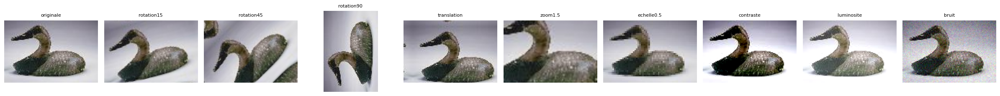

In [12]:
def translation(img, f=0.1):
    h, w = img.shape[:2]
    return cv2.warpAffine(img, np.float32([[1, 0, f * w], [0, 1, f * h]]), (w, h), borderMode=cv2.BORDER_REFLECT)
def rotation(img, angle):
    h, w = img.shape[:2]
    return cv2.warpAffine(img, cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0), (w, h), borderMode=cv2.BORDER_REFLECT)
def zoom(img, f=1.5):
    h, w = img.shape[:2]; ch, cw = int(h / f), int(w / f); y0, x0 = (h - ch) // 2, (w - cw) // 2
    return cv2.resize(img[y0:y0 + ch, x0:x0 + cw], (w, h), interpolation=cv2.INTER_LINEAR)
def contraste(img, a=1.6):
    return np.clip((img.astype(np.float32) - 128) * a + 128, 0, 255).astype(np.uint8)
def luminosite(img, b=50):
    return np.clip(img.astype(np.int16) + b, 0, 255).astype(np.uint8)
def bruit(img, s=12):
    rng = np.random.default_rng(0)
    return np.clip(img + rng.normal(0, s, img.shape), 0, 255).astype(np.uint8)

TRANSFORMATIONS = {
    'rotation15':  lambda im: rotation(im, 15),
    'rotation45':  lambda im: rotation(im, 45),
    'rotation90':  lambda im: np.ascontiguousarray(np.rot90(im)),
    'translation': translation,
    'zoom1.5':     zoom,
    'echelle0.5':  lambda im: cv2.resize(im, None, fx=.5, fy=.5, interpolation=cv2.INTER_AREA),
    'contraste':   contraste,
    'luminosite':  luminosite,
    'bruit':       bruit,
}
NB_PAR_CATEGORIE = 6
SOURCES = [n for n in REQ_BASE.values() if n]
for c in sorted({categorie(n) for n in NOMS_ORIG}):
    dispo = [n for n in NOMS_ORIG if categorie(n) == c and n not in SOURCES]
    SOURCES += random.sample(dispo, NB_PAR_CATEGORIE - sum(categorie(s) == c for s in SOURCES))

IMAGES_AUG = {f'{s}__{t}': f(IMAGES[s]) for s in SOURCES for t, f in TRANSFORMATIONS.items()}
TOUTES = {**IMAGES, **IMAGES_AUG}
NOMS = list(TOUTES)
print(f'{len(SOURCES)} images sources x {len(TRANSFORMATIONS)} transformations = {len(IMAGES_AUG)} nouvelles images')
print(f'Base augmentée : {len(NOMS)} images')

ex = REQ_BASE[list(REQ_BASE)[-1]]
fig, axes = plt.subplots(1, len(TRANSFORMATIONS) + 1, figsize=(2.4 * (len(TRANSFORMATIONS) + 1), 2.4))
axes[0].imshow(IMAGES[ex]); axes[0].set_title('originale', fontsize=8)
for ax, t in zip(axes[1:], TRANSFORMATIONS): ax.imshow(IMAGES_AUG[f'{ex}__{t}']); ax.set_title(t, fontsize=8)
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

In [13]:
# Description des images ajoutées, puis matrices S et P sur toute la base augmentée.
# On ne recalcule pas les similarités déjà connues entre images d'origine : S_aug = [[S, X], [Xᵀ, Y]]
t0 = time.time()
DESC_AUG = decrire_base(IMAGES_AUG)
for m in METHODES:
    if m[1] == 'Invariants':
        DESC_AUG[m] = [(d - STATS_INV[m][0]) / STATS_INV[m][1] for d in DESC_AUG[m]]
print(f'Description des images ajoutées : {time.time()-t0:.0f}s')

S_AUG, P_AUG = {}, {}
for m in METHODES:
    t0 = time.time()
    tous = DESC[m] + DESC_AUG[m]
    X = matrice_S(DESC_AUG[m], tous)                 # nouvelles images contre toute la base
    n = len(NOMS_ORIG)
    Sa = np.zeros((len(NOMS), len(NOMS)), dtype=np.int32)
    Sa[:n, :n] = S[m]; Sa[n:, :] = X; Sa[:n, n:] = X[:, :n].T
    Sa = symetriser(Sa)
    S_AUG[m] = Sa; P_AUG[m] = normaliser(Sa)
    tag = NOM_M(m).replace(' + ', '_')
    pd.DataFrame(Sa, index=NOMS, columns=NOMS).to_csv(os.path.join(OUT_DIR, f'S_augmentee_{tag}.csv'))
    pd.DataFrame(P_AUG[m], index=NOMS, columns=NOMS).round(4).to_csv(os.path.join(OUT_DIR, f'P_augmentee_{tag}.csv'))
    print(f'{NOM_M(m):22s} : {Sa.shape}, symétrique = {np.array_equal(Sa, Sa.T)} ({time.time()-t0:.0f}s)')

Description des images ajoutées : 40s
Harris + SIFT          : (486, 486), symétrique = True (49s)
Harris + Invariants    : (486, 486), symétrique = True (39s)
SIFT + SIFT            : (486, 486), symétrique = True (61s)
SIFT + Invariants      : (486, 486), symétrique = True (34s)


<h2>IV. Robustesse vis-à-vis des transformations</h2>

Pour chaque image transformée, on cherche son image d'origine parmi les 270 images de la base initiale :
- **Top-1** : proportion des cas où l'image d'origine est la plus similaire ;
- **rang moyen** de l'image d'origine (1 = parfait) ;
- **P moyen** : similarité normalisée moyenne entre l'image transformée et son originale.

La même mesure est faite avec la meilleure combinaison de descripteurs globaux de la première partie (histogramme HSV χ², moments Lab, LBP χ², HOG, pondérés), pour comparer les deux approches.

In [14]:
# ---- Approche globale (meilleure configuration de la partie 1), recalculée sur la base augmentée
def hist_hsv(img):
    h = cv2.calcHist([cv2.cvtColor(img, cv2.COLOR_RGB2HSV)], [0, 1, 2], None, [8, 3, 3], [0, 180, 0, 256, 0, 256]).ravel()
    return h / h.sum()
def moments_lab(img):
    x = cv2.cvtColor(img, cv2.COLOR_RGB2LAB).reshape(-1, 3).astype(np.float64) / 255
    mu = x.mean(0); return np.concatenate([mu, x.std(0), np.cbrt(((x - mu) ** 3).mean(0))])
def lbp(img):
    l = local_binary_pattern(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), 8, 1, method='uniform')
    return np.histogram(l, bins=np.arange(11), density=True)[0]
def hog_desc(img):
    g = cv2.resize(cv2.cvtColor(img, cv2.COLOR_RGB2GRAY), (128, 128), interpolation=cv2.INTER_AREA)
    return hog(g, orientations=8, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm='L2-Hys')

def dist(q, M, metrique):
    if metrique == 'chi2': return 0.5 * ((M - q) ** 2 / (M + q + 1e-10)).sum(1)
    return np.linalg.norm(M - q, axis=1)

GLOBAL = {'hist': (hist_hsv, 'chi2', 2), 'lab': (moments_lab, 'eucl', 1), 'lbp': (lbp, 'chi2', 2), 'hog': (hog_desc, 'eucl', 2)}
BLOCS_G = {k: np.array([f(TOUTES[n]) for n in NOMS]) for k, (f, _, _) in GLOBAL.items()}
D_G = np.zeros((len(NOMS), len(NOMS)))
for k, (_, met, w) in GLOBAL.items():
    Dk = np.array([dist(BLOCS_G[k][i], BLOCS_G[k], met) for i in range(len(NOMS))])
    D_G += w * Dk / (np.median(Dk, axis=1, keepdims=True) + 1e-10)
SIM_G = -D_G     # similarité = - distance (plus grand = plus proche)

TOUTES_SIM = {NOM_M(m): P_AUG[m] for m in METHODES}
TOUTES_SIM['Global (partie 1)'] = SIM_G

In [15]:
n = len(NOMS_ORIG)
lignes = []
for i, nom in enumerate(NOMS[n:], start=n):
    src, t = nom.split('__'); j_src = NOMS_ORIG.index(src)
    for meth, M in TOUTES_SIM.items():
        s = M[i, :n].astype(float)
        rang = 1 + (s > s[j_src]).sum()
        lignes.append({'transformation': t, 'méthode': meth, 'top1': rang == 1, 'rang': rang,
                       'P': M[i, j_src] if meth != 'Global (partie 1)' else np.nan})
ROB = pd.DataFrame(lignes)
ordre_m = list(TOUTES_SIM)
top1 = ROB.pivot_table(index='transformation', columns='méthode', values='top1', aggfunc='mean')[ordre_m].loc[list(TRANSFORMATIONS)]
rang = ROB.pivot_table(index='transformation', columns='méthode', values='rang', aggfunc='mean')[ordre_m].loc[list(TRANSFORMATIONS)]
Pm = ROB.pivot_table(index='transformation', columns='méthode', values='P', aggfunc='mean')[ordre_m[:-1]].loc[list(TRANSFORMATIONS)]
top1.loc['MOYENNE'] = top1.mean(); rang.loc['MOYENNE'] = rang.mean(); Pm.loc['MOYENNE'] = Pm.mean()
print('Top-1 : proportion des images transformées dont l\'originale est retrouvée en 1re position')
display(top1.style.background_gradient(cmap='RdYlGn', vmin=0, vmax=1).format('{:.2f}'))
print(f'Rang moyen de l\'image originale (1 = parfait, sur {n} images)')
display(rang.style.background_gradient(cmap='RdYlGn_r', vmin=1, vmax=30).format('{:.1f}'))
print('Similarité normalisée moyenne P(image transformée, originale)')
display(Pm.style.background_gradient(cmap='RdYlGn', vmin=0, vmax=1).format('{:.2f}'))

Top-1 : proportion des images transformées dont l'originale est retrouvée en 1re position


méthode,Harris + SIFT,Harris + Invariants,SIFT + SIFT,SIFT + Invariants,Global (partie 1)
transformation,,,,,
rotation15,0.58,0.96,1.00,1.00,0.92
rotation45,0.38,0.92,1.00,1.00,0.83
rotation90,1.00,1.00,1.00,1.00,1.00
translation,1.00,1.00,1.00,1.00,0.92
zoom1.5,0.25,0.25,0.79,0.42,0.50
echelle0.5,0.17,0.17,0.12,0.04,1.00
contraste,0.96,0.04,1.00,0.17,0.96
luminosite,1.00,0.17,1.00,0.50,0.96
bruit,0.83,1.00,1.00,1.00,0.46


Rang moyen de l'image originale (1 = parfait, sur 270 images)


méthode,Harris + SIFT,Harris + Invariants,SIFT + SIFT,SIFT + Invariants,Global (partie 1)
transformation,,,,,
rotation15,1.4,1.0,1.0,1.0,1.1
rotation45,2.9,1.1,1.0,1.0,1.5
rotation90,1.0,1.0,1.0,1.0,1.0
translation,1.0,1.0,1.0,1.0,1.2
zoom1.5,7.7,10.3,1.8,20.5,10.8
echelle0.5,18.3,18.8,32.4,49.3,1.0
contraste,1.0,50.7,1.0,54.0,1.0
luminosite,1.0,25.2,1.0,13.8,1.0
bruit,1.2,1.0,1.0,1.0,51.1


Similarité normalisée moyenne P(image transformée, originale)


méthode,Harris + SIFT,Harris + Invariants,SIFT + SIFT,SIFT + Invariants
transformation,,,,
rotation15,0.57,0.56,0.60,0.54
rotation45,0.49,0.52,0.58,0.50
rotation90,1.00,1.00,0.95,0.86
translation,0.84,0.88,0.87,0.87
zoom1.5,0.42,0.37,0.53,0.32
echelle0.5,0.46,0.47,0.44,0.31
contraste,0.66,0.29,0.67,0.29
luminosite,0.84,0.30,0.84,0.33
bruit,0.62,0.76,0.74,0.75


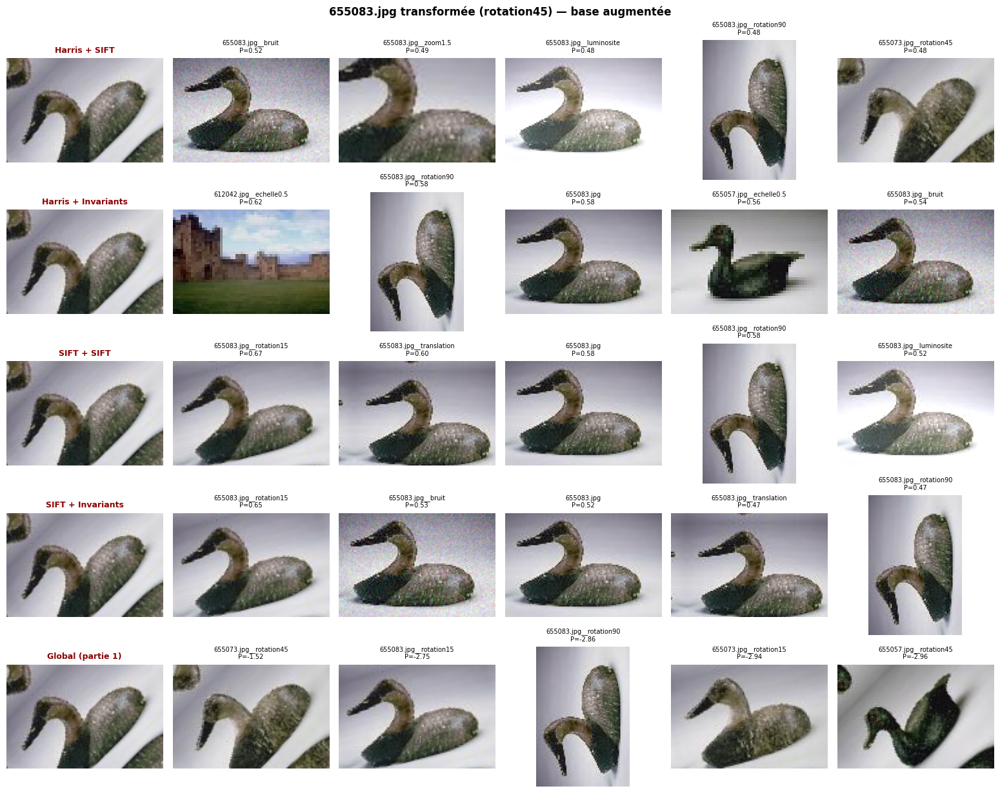

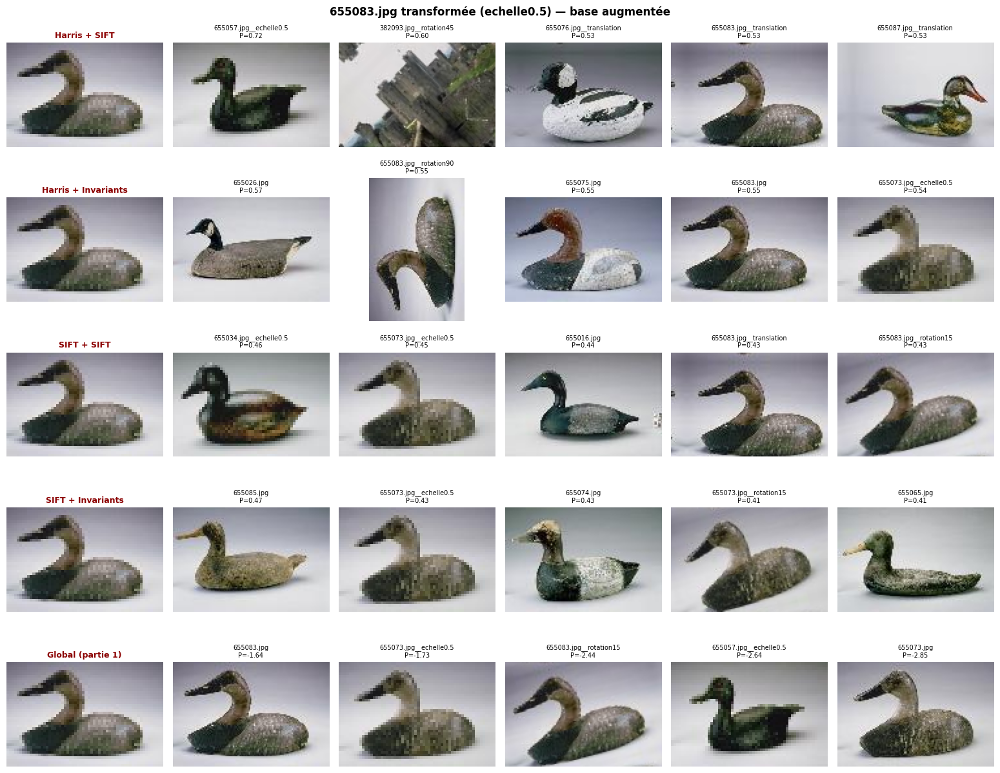

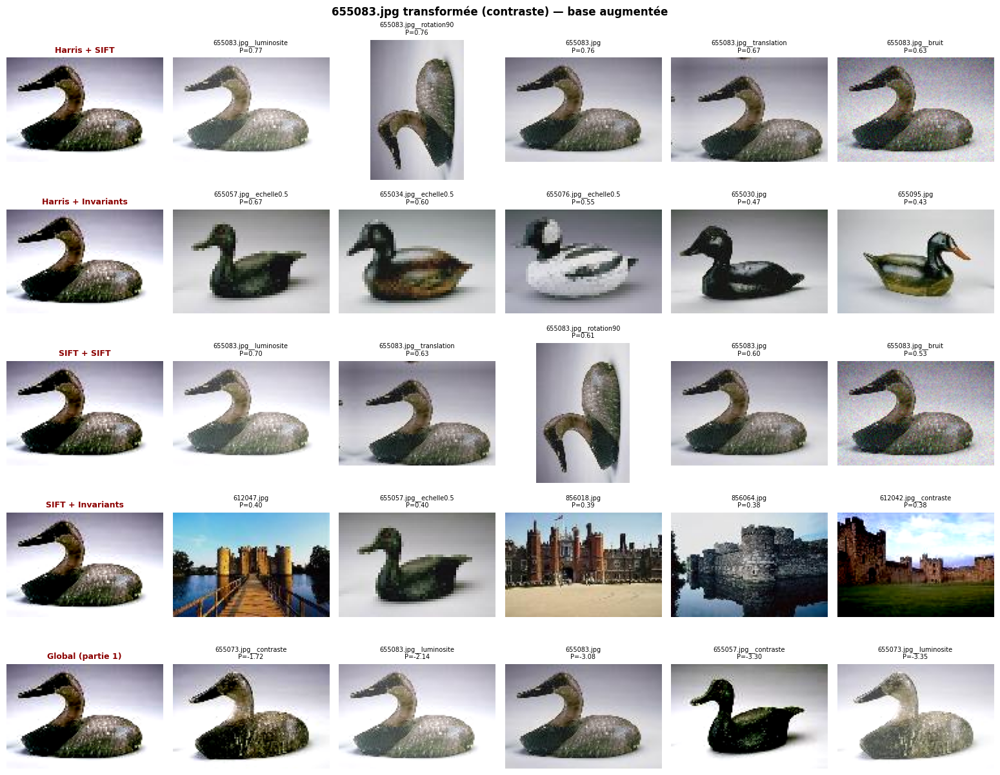

In [16]:
# Exemple visuel : une image requête transformée, et les 5 images les plus similaires dans la base augmentée
req_nom = REQ_BASE[list(REQ_BASE)[-1]]
for t in ['rotation45', 'echelle0.5', 'contraste']:
    i = NOMS.index(f'{req_nom}__{t}')
    afficher_lignes(TOUTES[NOMS[i]], {meth: plus_similaires(M, i, noms=NOMS) for meth, M in TOUTES_SIM.items()},
                    f'{req_nom} transformée ({t}) — base augmentée', images=TOUTES)

### Interprétation — robustesse aux transformations

Ici, la question est : peut-on retrouver **la même image** après transformation ? C'est le cas d'usage pour lequel les descripteurs locaux ont été conçus.

**SIFT + SIFT est la méthode la plus robuste** (Top-1 moyen **0,88**, contre 0,84 pour l'approche globale) :
- **Rotations de 15°, 45° et 90°, translation, bruit : 1,00.** Chaque point a sa propre orientation (invariance à la rotation), le descripteur est relatif à la position du point (invariance à la translation), et le lissage gaussien du détecteur résiste au bruit.
- **Contraste et luminosité : 1,00.** SIFT est construit à partir des **gradients**, qui ne sont pas affectés par un décalage de luminosité, et la normalisation L2 annule un changement de contraste.
- **Zoom ×1,5 : 0,79**, contre 0,25 avec Harris et 0,50 avec l'approche globale. C'est le seul détecteur multi-échelle : un point détecté à une échelle est retrouvé à l'échelle correspondante dans l'image agrandie.

**Le détecteur compte autant que le descripteur :**
- **Harris + SIFT** perd une grande partie de la robustesse à la rotation (0,58 à 15° et 0,38 à 45°). Harris travaille à une seule échelle, et l'orientation est estimée à partir d'un petit voisinage. Elle est donc moins fiable que celle calculée par SIFT, alors que le descripteur SIFT en dépend directement.
- La rotation de 90° reste parfaite (1,00) : c'est une simple permutation des pixels, donc les mêmes coins et les mêmes gradients sont retrouvés.
- Avec Harris, le zoom chute à 0,25 : la taille du voisinage est fixe, donc les points de l'image agrandie ne décrivent plus la même zone.

**Les invariants différentiels sont robustes à la géométrie, pas à la photométrie :**
- **Rotations (0,92 à 1,00) :** ils sont invariants **par construction** (combinaisons des dérivées qui ne dépendent pas du repère), sans avoir besoin d'estimer une orientation. C'est pourquoi Harris + Invariants (0,96 et 0,92) est bien meilleur que Harris + SIFT sur les rotations.
- **Bruit (1,00) :** les dérivées sont calculées après un lissage gaussien.
- **Contraste (0,04 à 0,17) et luminosité (0,17 à 0,50) :** échec, avec un rang moyen de l'originale autour de 50 sur 270. Les invariants contiennent l'intensité $L$ elle-même et des produits de dérivées, qui changent directement quand on multiplie ou décale les niveaux de gris. Il faudrait des invariants photométriques (rapports de dérivées) ou normaliser le patch avant de calculer les invariants.

**Ce qui fait échouer toutes les méthodes locales : la réduction ×0,5 (0,04 à 0,17).** Une image de 60×40 pixels n'a presque plus de structure locale. Les coins et les blobs disparaissent ou fusionnent, et on ne retrouve plus les mêmes points. À l'inverse, l'approche globale atteint **1,00** : les proportions de couleurs, la texture moyenne et le HOG calculé après redimensionnement ne changent presque pas.

**Ce qui fait échouer l'approche globale : le bruit (0,46, rang moyen 51).** Le bruit modifie l'histogramme de couleurs et surtout les motifs LBP, qui sont calculés sur des voisinages d'un pixel. Les descripteurs locaux, eux, retrouvent l'image dans 83 à 100 % des cas.

**Exemples visuels.**
- **Rotation de 45° :** SIFT + SIFT renvoie d'abord les autres versions du même leurre (rotation de 15°, translation, originale). La méthode globale, elle, se laisse attirer par d'autres leurres tournés de 45° (`655073__rotation45`, `655057__rotation45`) : elle reconnaît la transformation plutôt que l'objet.
- **Contraste :** SIFT + Invariants renvoie des châteaux, alors que SIFT + SIFT renvoie les autres versions de la même image.

<h2>V. Lien avec l'approche globale</h2>

Évaluation sur les 270 images de la base d'origine : chaque image sert de requête, et on mesure la précision@k et la mAP :
- au niveau des **4 catégories COREL** (comme dans la première partie) ;
- au niveau des **2 groupes** de l'énoncé (leurres / châteaux).

In [17]:
def scores(Sim, labels, ks=(5, 10)):
    Sim = Sim.astype(float).copy(); np.fill_diagonal(Sim, -np.inf)
    o = np.argsort(-Sim, axis=1)[:, :-1]
    pert = labels[o] == labels[:, None]
    r = {f'P@{k}': pert[:, :k].mean() for k in ks}
    prec = np.cumsum(pert, 1) / np.arange(1, pert.shape[1] + 1)
    r['mAP'] = ((prec * pert).sum(1) / np.maximum(pert.sum(1), 1)).mean()
    return r

n = len(NOMS_ORIG)
lab_cat = np.array([categorie(x) for x in NOMS_ORIG]); lab_th = np.array([theme(x) for x in NOMS_ORIG])
EVAL = {}
for meth, M in TOUTES_SIM.items():
    sc_c, sc_t = scores(M[:n, :n], lab_cat), scores(M[:n, :n], lab_th)
    EVAL[meth] = {**{f'{k} (catégorie)': v for k, v in sc_c.items()}, **{f'{k} (groupe)': v for k, v in sc_t.items()}}
EVAL = pd.DataFrame(EVAL).T
display(EVAL.style.background_gradient(cmap='Greens', axis=0).format('{:.3f}'))

hasard_c = sum((lab_cat == c).sum() ** 2 for c in set(lab_cat)) / n ** 2
hasard_t = sum((lab_th == c).sum() ** 2 for c in set(lab_th)) / n ** 2
print(f'Référence du hasard : {hasard_c:.2f} (catégories), {hasard_t:.2f} (groupes)')

,P@5 (catégorie),P@10 (catégorie),mAP (catégorie),P@5 (groupe),P@10 (groupe),mAP (groupe)
Harris + SIFT,0.364,0.361,0.374,0.484,0.500,0.658
Harris + Invariants,0.382,0.376,0.362,0.584,0.613,0.668
SIFT + SIFT,0.359,0.373,0.339,0.820,0.809,0.737
SIFT + Invariants,0.414,0.404,0.360,0.816,0.793,0.704
Global (partie 1),0.588,0.581,0.562,0.996,0.995,0.975


Référence du hasard : 0.26 (catégories), 0.57 (groupes)


In [18]:
# Coût des deux approches
cout = {}
for m in METHODES:
    cout[NOM_M(m)] = {'valeurs par image (moyenne)': np.mean([d.size for d in DESC[m]]),
                      'comparaison': 'appariement réciproque (nₐ x n_b distances)'}
cout['Global (partie 1)'] = {'valeurs par image (moyenne)': sum(BLOCS_G[k].shape[1] for k in BLOCS_G),
                             'comparaison': '4 distances entre vecteurs'}
display(pd.DataFrame(cout).T)

,valeurs par image (moyenne),comparaison
Harris + SIFT,14136.414815,appariement réciproque (nₐ x n_b distances)
Harris + Invariants,1656.611111,appariement réciproque (nₐ x n_b distances)
SIFT + SIFT,15360.0,appariement réciproque (nₐ x n_b distances)
SIFT + Invariants,1442.555556,appariement réciproque (nₐ x n_b distances)
Global (partie 1),1659,4 distances entre vecteurs


### Interprétation — comparaison avec l'approche globale

**Retrouver une image de la même catégorie : l'approche globale est nettement meilleure.**

| Méthode | P@5 (catégorie) | mAP (catégorie) | P@5 (groupe) | mAP (groupe) |
|---|---|---|---|---|
| Harris + SIFT | 0,364 | 0,374 | 0,484 | 0,658 |
| Harris + Invariants | 0,382 | 0,362 | 0,584 | 0,668 |
| SIFT + SIFT | 0,359 | 0,339 | **0,820** | **0,737** |
| SIFT + Invariants | **0,414** | 0,360 | 0,816 | 0,704 |
| Global (partie 1) | **0,588** | **0,562** | **0,996** | **0,975** |
| *Hasard* | *0,26* | | *0,57* | |

- Pour les **catégories**, les méthodes locales font à peine mieux que le hasard (0,36 à 0,41 contre 0,26).
- Pour les **2 groupes** (leurres / châteaux), les méthodes à détecteur SIFT atteignent une précision@5 de 0,82, mais l'approche globale sépare les deux groupes **presque parfaitement** (0,996).
- Harris + SIFT est même **sous le hasard** au niveau des groupes (0,484 contre 0,57). Ce sont les images « similaires à tout » vues sur la carte de chaleur : avec peu de points Harris, la normalisation par $\min(S_{ii}, S_{jj})$ leur donne un P élevé avec n'importe quelle image.

**Pourquoi :**
- Les descripteurs locaux sont faits pour reconnaître **la même scène ou le même objet**, en retrouvant les mêmes points. Deux leurres différents ou deux châteaux différents n'ont pas les mêmes coins au même endroit : ils se ressemblent par leur **apparence d'ensemble** (fond gris uniforme, ciel et herbe), ce que les descripteurs globaux captent directement.
- Sans test du rapport de Lowe ni vérification géométrique, le nombre de couples réciproques mesure surtout la ressemblance des petites textures, et il est noyé par les faux appariements.
- Les images de 120×80 pixels sont trop petites pour fournir beaucoup de points vraiment caractéristiques.

**Coût :**
- Une image décrite par SIFT occupe environ **15 000 valeurs**, contre 1 659 pour la description globale.
- Comparer deux images demande de calculer toutes les distances entre leurs points (environ 120 × 120 distances en dimension 128), au lieu de 4 distances entre vecteurs.
- Le calcul de la matrice 270×270 prend environ 30 secondes par méthode, alors que l'approche globale est quasi instantanée.

**Les deux approches sont complémentaires :**

| Situation | Meilleure approche |
|---|---|
| Rotation, translation, bruit, contraste, zoom | **Locale (SIFT + SIFT)** |
| Changement d'échelle (petite image) | **Globale** |
| Retrouver la même catégorie ou le même groupe | **Globale** |
| Coût en mémoire et en calcul | **Globale** |

**Pistes d'amélioration :**
- Ajouter au matching le **test du rapport de Lowe** et une **vérification géométrique (RANSAC)**, pour ne compter que les vrais appariements.
- Construire un **sac de mots visuels** (*bag of visual words*) : regrouper les descripteurs SIFT en un vocabulaire par k-means et décrire chaque image par l'histogramme de ses « mots ». On obtient un descripteur global à partir de descripteurs locaux, qui convient à la recherche par catégorie et se compare beaucoup plus rapidement.
- **Combiner** les scores locaux et globaux : le global retrouve la catégorie, le local confirme la correspondance précise.

<h2>Conclusion</h2>

Dans cette deuxième partie, on a remplacé la description globale des images par une description **locale** :
1. Les points d'intérêt sont détectés avec **Harris** (coins, une échelle) et **SIFT** (blobs, plusieurs échelles).
2. Ils sont décrits par **SIFT** (128 valeurs, gradients orientés) et par les **invariants différentiels** (15 valeurs, dérivées gaussiennes jusqu'à l'ordre 2).
3. La similarité est le nombre de **couples réciproques**. Les matrices S et P (N×N, symétriques, Pᵢᵢ = 1) sont enregistrées dans des fichiers CSV.

**Principaux enseignements :**
- **Robustesse : SIFT + SIFT est le meilleur.** Il retrouve l'image d'origine dans 88 % des cas en moyenne et à 100 % pour les rotations, la translation, le bruit, le contraste et la luminosité, grâce à ses invariances par construction (échelle, orientation, gradients normalisés).
- **Le détecteur compte :** Harris, à une seule échelle, perd la robustesse au zoom et aux petites rotations.
- **Les invariants différentiels** sont invariants aux rotations par construction, mais pas aux changements photométriques (contraste, luminosité).
- **Toutes les méthodes locales échouent sur la réduction d'échelle** : les images deviennent trop petites (60×40) pour garder leurs points d'intérêt.
- **Pour retrouver des images de la même catégorie, l'approche globale de la partie 1 reste bien meilleure** (mAP 0,56 contre 0,34 à 0,37 ; séparation leurres / châteaux à 99,6 % contre 82 % au mieux). Elle est aussi environ 9 fois plus compacte et bien plus rapide.

**En résumé :** les descripteurs locaux répondent à la question « est-ce la même image, même transformée ? », et les descripteurs globaux à la question « est-ce le même type d'image ? ». Un moteur de recherche complet gagnerait à combiner les deux. On peut aussi passer d'une approche à l'autre avec un sac de mots visuels construit à partir des descripteurs SIFT, en ajoutant le test du rapport de Lowe et une vérification géométrique pour fiabiliser les appariements.